In [1]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]) # [-1, 1]
train_data = datasets.CIFAR10(root="~/.cache/", transform=transform, train=True, download=True)
test_data = datasets.CIFAR10(root="~/.cache/", transform=transform, train=False)
print(train_data[0][0].shape)
print(test_data[0][0].dtype)

Files already downloaded and verified
torch.Size([3, 32, 32])
torch.float32


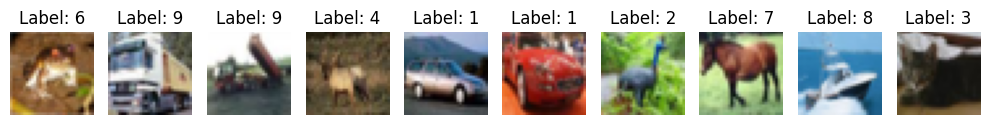

In [2]:
import matplotlib.pyplot as plt

# 遍历前10张图片
fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = train_data[i]
    ax = axes[i]  # 获取当前子图
    image = (image + 1) / 2 # 将[-1, 1]范围的图像转换为[0, 1]范围 
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

In [3]:
import torch
import torch.nn.functional as F

## Train

In [6]:
from ddpm import DDPM
from config import DiTConfig
from dit import DiT

batch_size = 256
num_epoch = 200

config = DiTConfig()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ddpm = DDPM(config.n_steps, device)
model = DiT(config).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epoch)
dataloader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True)

for epoch in range(num_epoch):
    for x, label in dataloader:
        x = x.to(device)
        label = label.to(device)

        t = torch.randint(0, config.n_steps, size=(x.size(0),), device=device)
        x_t, noise = ddpm.forward_step(x, t)
        # 损失计算
        loss = F.mse_loss(model(x_t, label, t), noise)  # 预测噪声
        
        optimizer.zero_grad()  # 梯度清零
        loss.backward()  # 损失回传
        # torch.nn.utils.clip_grad_norm_(model.parameters(),1.)  # 梯度裁剪
        optimizer.step()    
    scheduler.step()  # 每个 epoch 结束后调用

    if epoch == 0 or (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch + 1}/{num_epoch}, Loss: {loss.item():.4f}')

Epoch 1/200, Loss: 0.2123
Epoch 10/200, Loss: 0.1116
Epoch 20/200, Loss: 0.1186
Epoch 30/200, Loss: 0.1087
Epoch 40/200, Loss: 0.1222
Epoch 50/200, Loss: 0.1243
Epoch 60/200, Loss: 0.1007
Epoch 70/200, Loss: 0.1045
Epoch 80/200, Loss: 0.1161
Epoch 90/200, Loss: 0.0909
Epoch 100/200, Loss: 0.1087
Epoch 110/200, Loss: 0.0898
Epoch 120/200, Loss: 0.0918
Epoch 130/200, Loss: 0.1172
Epoch 140/200, Loss: 0.1036
Epoch 150/200, Loss: 0.1034
Epoch 160/200, Loss: 0.1011
Epoch 170/200, Loss: 0.1004
Epoch 180/200, Loss: 0.1011
Epoch 190/200, Loss: 0.1004
Epoch 200/200, Loss: 0.1136


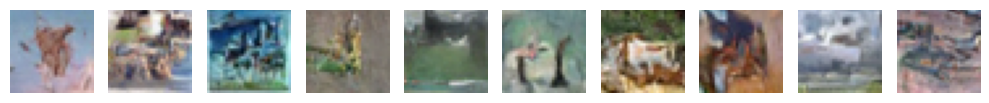

In [11]:
n_sample = 10
model.eval()
with torch.inference_mode():
    x_t = torch.randn(n_sample, 3, 32, 32, device=device)  # 使用初始数据
    label = torch.tensor([10]*n_sample, device=device) # random
    for i in reversed(range(config.n_steps)):
        t = torch.tensor([i] * x_t.size(0), device=device)
        eps = model(x_t, label, t)
        x_t = ddpm.reverse_step(x_t, eps, t)

x = x_t.clamp(-1.0, 1.0).cpu()
fig, axes = plt.subplots(1, n_sample, figsize=(n_sample, 2))
for i in range(n_sample):
    image = x[i]
    ax = axes[i]  # 获取当前子图
    image = (image + 1) / 2 # 将[-1, 1]范围的图像转换为[0, 1]范围 
    ax.imshow(image.permute(1, 2, 0))
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

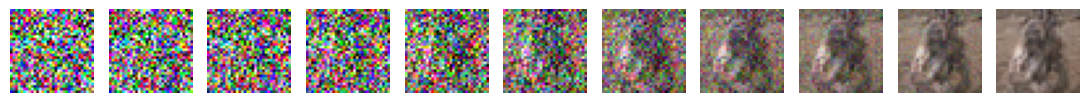

In [ ]:
model.eval()
with torch.inference_mode():
    x_t = torch.randn(1, 3, 32, 32, device=device)  # 使用初始数据
    label = torch.tensor([5], device=device) # horse
    x_seq = [x_t.squeeze().clamp(-1.0, 1.0).cpu()]
    for i in reversed(range(config.n_steps)):
        t = torch.tensor([i] * x_t.size(0), device=device)
        eps = model(x_t, label, t)
        x_t = ddpm.reverse_step(x_t, eps, t)
        x_seq.append(x_t.squeeze().clamp(-1.0, 1.0).cpu())

# plot picture
plt.rc('text',color='blue')
stride = config.n_steps // 10
x_seq = x_seq[::stride]
fig, axes = plt.subplots(1, 11, figsize=(11, 2))  # 1行11列的子图
for i in range(len(x_seq)):
    image = x_seq[i]
    ax = axes[i]  # 获取当前子图
    image = (image + 1) / 2 # 将[-1, 1]范围的图像转换为[0, 1]范围 
    ax.imshow(image.permute(1, 2, 0))
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

In [17]:
torch.save(model.state_dict, 'cifar10-250807.pt')